# Combined model (P01): photograph plus measurements

**Question.** Does giving a CNN the three automatically measured cup-to-disc ratios, on top of the photograph, improve glaucoma prediction over the photograph alone?

The design and the decision rule were written before any run (`docs/experiment_log.md`, "P01 design"). This notebook reads only the saved result tables in `docs/p01_evidence/` and the frozen record `docs/frozen_p01.json`, so it needs no patient data and runs in seconds. The 10 trainings and the one-shot test scoring were run on the university GPU cluster; the commands are in `hpc/README.md`.

| Arm | Sees |
|---|---|
| image only | the photograph (the Baseline B recipe) |
| combined | the photograph plus the three predicted ratios, joined before the last layer |
| measurements only | the three ratios alone (Baseline A, not retrained) |

Each neural arm has 5 seeds (2440 to 2444). An arm's score is the mean logit of its seeds.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from glaucoma_project import REPO_ROOT

EVIDENCE = REPO_ROOT / "docs" / "p01_evidence"
PARTITION_NAMES = {"in_domain_test": "CHAKSU test", "external_test": "PAPILA (external)"}
pd.set_option("display.precision", 3)

## 1. The frozen record

Before any test image was opened, the code version and the SHA-256 hash of every checkpoint, the measurements file and the split file were recorded.

In [2]:
record = json.loads((REPO_ROOT / "docs" / "frozen_p01.json").read_text())
files = pd.DataFrame([{"file": name, "path": entry["path"], "sha256 (first 12)": entry["sha256"][:12]}
                      for name, entry in record["files"].items()])
print("frozen at commit", record["git_commit"][:7], "| code paths guarded:", len(record["code_paths"]))
print("seeds:", record["settings"]["study"]["seeds"], "| bootstrap resamples:", record["settings"]["study"]["n_bootstrap"])
display(files)

frozen at commit 02becaa | code paths guarded: 12
seeds: [2440, 2441, 2442, 2443, 2444] | bootstrap resamples: 2000


,file,path,sha256 (first 12)
0,image_only_seed2440,runs/p01/p01_image_only_seed2440/best.pt,ab3cc0d36937
1,image_only_seed2441,runs/p01/p01_image_only_seed2441/best.pt,f73cf9aeba9e
2,image_only_seed2442,runs/p01/p01_image_only_seed2442/best.pt,b8cecaecce53
3,image_only_seed2443,runs/p01/p01_image_only_seed2443/best.pt,3c527bdb7305
4,image_only_seed2444,runs/p01/p01_image_only_seed2444/best.pt,43b896ec25d6
5,combined_seed2440,runs/p01/p01_combined_seed2440/best.pt,8e42e9350b8c
6,combined_seed2441,runs/p01/p01_combined_seed2441/best.pt,0b30decd2ffb
7,combined_seed2442,runs/p01/p01_combined_seed2442/best.pt,ae763c8d25cb
8,combined_seed2443,runs/p01/p01_combined_seed2443/best.pt,7923ac19b4e3
9,combined_seed2444,runs/p01/p01_combined_seed2444/best.pt,4daf308861ba


## 2. Development runs

Ten trainings on one RTX 5000 Ada GPU. Validation AUROC chose the epoch (it is selection data, not independent evidence). Training error falls to almost zero in both arms.

In [3]:
runs = pd.read_csv(EVIDENCE / "development_runs.csv")
display(runs)
display(runs.groupby("arm").agg(validation_auroc_mean=("validation_auroc", "mean"),
                                validation_auroc_min=("validation_auroc", "min"),
                                validation_auroc_max=("validation_auroc", "max"),
                                final_train_bce_mean=("final_train_bce", "mean")))

,arm,seed,epochs_run,best_epoch,validation_auroc,final_train_bce,seconds_per_epoch,gpu,torch,code_commit
0,combined,2440,14,8,0.840,1.190e-02,3.7,NVIDIA RTX 5000 Ada Generation,2.11.0+cu128,c606261
1,combined,2441,16,10,0.852,3.300e-03,3.4,NVIDIA RTX 5000 Ada Generation,2.11.0+cu128,c606261
2,combined,2442,19,13,0.847,5.000e-04,3.4,NVIDIA RTX 5000 Ada Generation,2.11.0+cu128,c606261
3,combined,2443,14,8,0.851,1.150e-02,3.4,NVIDIA RTX 5000 Ada Generation,2.11.0+cu128,c606261
4,combined,2444,14,8,0.830,6.700e-03,3.5,NVIDIA RTX 5000 Ada Generation,2.11.0+cu128,c606261
5,image_only,2440,14,8,0.838,1.180e-02,3.4,NVIDIA RTX 5000 Ada Generation,2.11.0+cu128,c606261
6,image_only,2441,16,10,0.848,3.000e-03,3.6,NVIDIA RTX 5000 Ada Generation,2.11.0+cu128,c606261
7,image_only,2442,17,11,0.834,1.700e-03,3.4,NVIDIA RTX 5000 Ada Generation,2.11.0+cu128,c606261
8,image_only,2443,14,8,0.845,8.700e-03,3.4,NVIDIA RTX 5000 Ada Generation,2.11.0+cu128,c606261
9,image_only,2444,17,11,0.824,8.000e-04,3.4,NVIDIA RTX 5000 Ada Generation,2.11.0+cu128,c606261


,validation_auroc_mean,validation_auroc_min,validation_auroc_max,final_train_bce_mean
arm,,,,
combined,0.844,0.830,0.852,0.007
image_only,0.838,0.824,0.848,0.005


## 3. Primary comparison

Combined minus image-only, AUC of the seed-averaged scores, paired bootstrap over whole patient groups (2,000 resamples), each test set on its own. **Decision rule:** an improvement is claimed only if the 95% interval excludes 0.

,partition,n_images,n_positives,combined AUC,image-only AUC,difference,ci_low,ci_high,verdict
0,in_domain_test,335,51,0.816,0.813,0.003,-0.005,0.011,not shown
1,external_test,420,87,0.770,0.764,0.006,-0.002,0.015,not shown


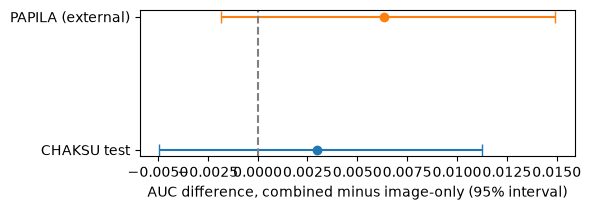

In [4]:
primary = pd.read_csv(EVIDENCE / "primary.csv")
primary["verdict"] = ["improvement" if low > 0 else "not shown" for low in primary.ci_low]
display(primary[["partition", "n_images", "n_positives", "auc_a", "auc_b", "difference", "ci_low", "ci_high", "verdict"]]
        .rename(columns={"auc_a": "combined AUC", "auc_b": "image-only AUC"}))

fig, ax = plt.subplots(figsize=(6, 2.2))
for y, row in enumerate(primary.itertuples()):
    ax.errorbar(row.difference, y, xerr=[[row.difference - row.ci_low], [row.ci_high - row.difference]], fmt="o", capsize=4)
ax.axvline(0, color="grey", linestyle="--")
ax.set_yticks(range(len(primary)), [PARTITION_NAMES[p] for p in primary.partition])
ax.set_xlabel("AUC difference, combined minus image-only (95% interval)")
fig.tight_layout()

## 4. Seed spread

The seed-to-seed spread of the difference shows how much of it is training noise. A run-to-run spread larger than the average difference means the gain is not reliable.

,partition,seed,combined,image_only,difference
0,in_domain_test,2440,0.793,0.790,0.003
1,in_domain_test,2441,0.810,0.817,-0.006
2,in_domain_test,2442,0.796,0.791,0.005
3,in_domain_test,2443,0.821,0.812,0.009
4,in_domain_test,2444,0.818,0.799,0.019
5,external_test,2440,0.736,0.740,-0.004
6,external_test,2441,0.772,0.761,0.012
7,external_test,2442,0.756,0.750,0.007
8,external_test,2443,0.775,0.758,0.017
9,external_test,2444,0.770,0.764,0.006


,mean,min,max,seeds ahead (of 5)
partition,,,,
external_test,0.007,-0.004,0.017,4
in_domain_test,0.006,-0.006,0.019,4


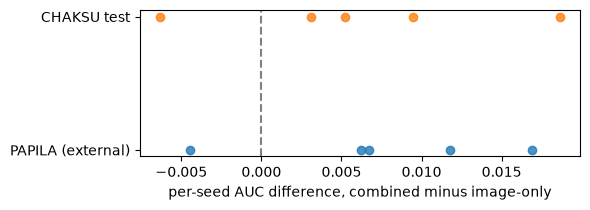

In [5]:
seeds = pd.read_csv(EVIDENCE / "per_seed.csv")
display(seeds)
summary = seeds.groupby("partition").difference.agg(["mean", "min", "max"])
summary["seeds ahead (of 5)"] = seeds.groupby("partition").difference.apply(lambda d: int((d > 0).sum()))
display(summary)

fig, ax = plt.subplots(figsize=(6, 2.2))
for y, (partition, group) in enumerate(seeds.groupby("partition")):
    ax.scatter(group.difference, [y] * len(group), alpha=0.8)
ax.axvline(0, color="grey", linestyle="--")
ax.set_yticks(range(2), [PARTITION_NAMES[p] for p in sorted(seeds.partition.unique())])
ax.set_xlabel("per-seed AUC difference, combined minus image-only")
fig.tight_layout()

## 5. Secondary comparison: each arm against the measurements alone

On the images both have scores for. A negative difference means the network is worse than the three ratios in a simple classifier.

In [6]:
secondary = pd.read_csv(EVIDENCE / "secondary.csv")
display(secondary[["partition", "comparison", "n_images", "auc_a", "auc_b", "difference", "ci_low", "ci_high"]])

,partition,comparison,n_images,auc_a,auc_b,difference,ci_low,ci_high
0,in_domain_test,image_only minus measurements_only,326,0.812,0.943,-0.131,-0.199,-0.061
1,in_domain_test,combined minus measurements_only,326,0.815,0.943,-0.129,-0.197,-0.059
2,external_test,image_only minus measurements_only,418,0.765,0.731,0.034,-0.043,0.110
3,external_test,combined minus measurements_only,418,0.770,0.731,0.039,-0.033,0.111


## 6. Each arm on its own

AUC with 95% interval, and sensitivity and specificity at the threshold taken from the seed-averaged validation scores (the Baseline B rule: highest specificity at 90% sensitivity). The threshold metrics are descriptive only.

In [7]:
arms = pd.read_csv(EVIDENCE / "arm_metrics.csv")
view = arms[arms.metric.isin(["auroc", "sensitivity", "specificity"])]
display(view.pivot_table(index=["partition", "arm"], columns="metric", values="estimate"))
display(view[view.metric == "auroc"][["partition", "arm", "estimate", "lower_95", "upper_95"]])

metric                     auroc  sensitivity  specificity
partition      arm                                        
external_test  combined    0.770        0.460        0.892
               image_only  0.764        0.391        0.910
in_domain_test combined    0.816        0.824        0.634
               image_only  0.813        0.824        0.623

,partition,arm,estimate,lower_95,upper_95
0,in_domain_test,image_only,0.813,0.745,0.874
6,in_domain_test,combined,0.816,0.749,0.876
12,external_test,image_only,0.764,0.695,0.828
18,external_test,combined,0.770,0.703,0.833


## 7. Images where no disc was found

The ratios of these images were filled with the training median. Too few images for a conclusion.

In [8]:
display(pd.read_csv(EVIDENCE / "no_disc.csv"))

,arm,partition,group,n,positives,auroc
0,image_only,in_domain_test,no_disc_found,0,0,NaN
1,image_only,in_domain_test,disc_found,335,51,0.813
2,image_only,external_test,no_disc_found,30,9,0.667
3,image_only,external_test,disc_found,390,78,0.771
4,combined,in_domain_test,no_disc_found,0,0,NaN
5,combined,in_domain_test,disc_found,335,51,0.816
6,combined,external_test,no_disc_found,30,9,0.651
7,combined,external_test,disc_found,390,78,0.778


## Reading the result

- **Improvement not shown** on either test set: both intervals include 0, and the seed spread is larger than the mean difference.
- On CHAKSU, the three ratios alone beat both networks by about 0.13 AUC. CHAKSU labels follow cup size, so CHAKSU favours measurements.
- On PAPILA, both networks are slightly ahead of the ratios, inside the noise.
- Both arms fit the training photographs almost perfectly (training error near 0), so the extra inputs add little. This is an explanation consistent with the numbers, not a tested cause.
- The result is for one way of combining the inputs (joined before the last layer, trained end to end). The two-step blend, which avoids fitting the labels first, is the next planned experiment (P01b).

## Reproduce

```bash
python -m glaucoma_project.measurements.classification_inputs --out runs/p01/measurements.csv
sbatch hpc/p01_train.sbatch                           # 10 trainings (2 arms x 5 seeds)
python -m glaucoma_project.combined_model.study freeze
python -m glaucoma_project.combined_model.study score   # opens the test sets once
python -m glaucoma_project.combined_model.analysis --scores runs/p01/final --out runs/p01/analysis
```

Details, cluster notes and expected run time: `hpc/README.md`.